# Intensity cap versus absolute cap

The emission target can now be imposed in two ways (`H2System.add_gwp_cap`, `H2System.add_robust_gwp_cap`,
`H2SystemTree.add_gwp_cap`):

- **absolute cap**: $GWP \le \epsilon$ [kg CO2e per year];
- **intensity cap**: $GWP \le \iota \cdot H_2^{own}$ [kg CO2e per kg H2], where $H_2^{own}$ is the hydrogen delivered
  against the demand minus the demand-penalty tiers D1 to D4.

The penalty tiers carry no emissions, so an absolute cap can be met by producing less and covering the shortfall with
penalty hydrogen. The intensity cap removes that loophole: every kilogram of own hydrogen has to meet the target. It is
also the form in which hydrogen policy thresholds are written (kg CO2e per kg H2). The comparison below uses the
50 % target of the sweeps, as an absolute cap (723.66 kt) and as the equivalent intensity (50 % of the cost-optimal
intensity), for the nominal coefficients and for the Scope 1 and Scope 3 boxes of the robust counterpart.

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Rahul Kakodkar", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.1.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"

In [1]:
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tvef_model as tm
from tvef_model import H2System, make_inputs, PARAMS

data = tm.load_case_data()
nominal = make_inputs(data)
pd.set_option('display.width', 180)

## Cost-optimal intensity

In [2]:
base = H2System(nominal, 'cost', 'eq')
base.solve(tee=False)
base.summary()
res0 = base.results()
GWP0, I0 = res0['global_warming_potential_network'][0], res0['gwp_intensity']
TARGET_PCT = 50
CAP = GWP0 * (1 - TARGET_PCT / 100)
INT = I0 * (1 - TARGET_PCT / 100)
print(f'\ncost-optimal intensity {I0:.3f} kg CO2e/kg H2  ->  50 % target: absolute cap {CAP:,.0f} kg, intensity cap {INT:.3f} kg/kg')
del base

Set parameter Username


Academic license - for non-commercial use only - expires 2027-03-30


termination : optimal
objective   : 257,643,902.36  (cost)
total cost  : 257,643,902.36 USD  (capex 182,438, fopex 1,414, vopex 42,144,705, purchase 215,315,345)
total GWP   : 1,447,319,755.91 kg CO2e  (scope 1 1,038,794,998, scope 2 31,945,361, scope 3 376,579,396)
hydrogen    : own 110,848,551 kg, penalty tiers 0 kg  ->  intensity 13.057 kg CO2e/kg H2 (nominal coefficients)
capacities  : ATR_CCS_R 0.0, ATR_CCS_R_OC 0.0, AWE 0.0, Grid 41.0, LiI 25.0, LiI_discharge 25.0, PEM 0.0, PV 600.0, SMR 23,566.1, SMRCCS 0.0, WF 650.0
storage     : LiI_Power_stored 142.18



cost-optimal intensity 13.057 kg CO2e/kg H2  ->  50 % target: absolute cap 723,659,878 kg, intensity cap 6.528 kg/kg


## Absolute versus intensity cap at the 50 % target

In [3]:
cases = [('nominal', {}), ('scope 1 box (Γ1 = 4)', {1: 4}), ('scope 3 box (Γ3 = 1)', {3: 1.0}),
         ('scope 2 box (Γ2 = 365)', {2: 365}), ('full box', {1: 4, 2: 365, 3: 1.0})]
rows = []
t0 = time.time()
for label, gamma in cases:
    for kind in ('absolute', 'intensity'):
        m = H2System(nominal, 'cost', 'geq')
        kw = dict(cap=CAP) if kind == 'absolute' else dict(intensity=INT)
        if gamma:
            m.add_robust_gwp_cap(gamma=gamma, band='0.75', **kw)
        else:
            m.add_gwp_cap(**kw)
        st = m.solve(tee=False)
        r = m.results() if st == 'optimal' else {}
        rv = m.robust_values() if (st == 'optimal' and gamma) else {}
        fr = m.frames() if st == 'optimal' else None
        rows.append({'budget': label, 'cap type': kind, 'status': st,
                     'cost [M USD]': r.get('objective', np.nan) / 1e6,
                     'own H2 [kt]': r.get('H2_own', np.nan) / 1e6, 'penalty H2 [kt]': r.get('H2_penalty', np.nan) / 1e6,
                     'nominal GWP [kt]': r.get('global_warming_potential_network', {}).get(0, np.nan) / 1e6,
                     'worst-case GWP [kt]': rv.get('worst_case_gwp', r.get('global_warming_potential_network', {}).get(0, np.nan)) / 1e6,
                     'nominal intensity': r.get('gwp_intensity', np.nan),
                     'worst-case intensity': rv.get('worst_case_intensity', r.get('gwp_intensity', np.nan)),
                     'SMR': fr['Cap_P']['SMR'] if fr else np.nan, 'ATR_CCS_R': fr['Cap_P']['ATR_CCS_R'] if fr else np.nan,
                     'ATR_CCS_R_OC': fr['Cap_P']['ATR_CCS_R_OC'] if fr else np.nan,
                     'PEM': fr['Cap_P']['PEM'] if fr else np.nan, 'AWE': fr['Cap_P']['AWE'] if fr else np.nan,
                     'battery [MWh]': fr['Cap_S'].iloc[0] if fr else np.nan})
        del m
print(f'{len(rows)} solves in {time.time() - t0:.0f} s')
cmp = pd.DataFrame(rows).set_index(['budget', 'cap type'])
cmp.round(3)

10 solves in 673 s


status  cost [M USD]  own H2 [kt]  penalty H2 [kt]  nominal GWP [kt]  worst-case GWP [kt]  nominal intensity  worst-case intensity       SMR  \
budget                 cap type                                                                                                                                                   
nominal                absolute   optimal       274.909      110.849            0.000           723.660              723.660              6.528                 6.528  4920.837   
                       intensity  optimal       274.909      110.849            0.000           723.660              723.660              6.528                 6.528  4920.837   
scope 1 box (Γ1 = 4)   absolute   optimal       301.626      110.849            0.000           436.068              723.660              3.934                 6.528     0.001   
                       intensity  optimal       301.626      110.849            0.000           436.068              723.660              3.934                 6.528     0.001   
scope 3 box (Γ3 = 1)   absolute   optimal       546.769      104.279            6.570           301.867              723.660              2.895                 6.940     0.001   
                       intensity  optimal       887.501       89.621           21.228           244.017              585.078              2.723                 6.528     0.001   
scope 2 box (Γ2 = 365) absolute   optimal       275.382      110.849            0.000           706.068              723.660              6.370                 6.528  4515.122   
                       intensity  optimal       275.382      110.849            0.000           706.068              723.660              6.370                 6.528  4515.122   
full box               absolute   optimal       968.103       86.128           24.720           231.060              723.660              2.683                 8.402     0.001   
                       intensity  optimal      2428.632       54.577           56.271           113.755              356.300              2.084                 6.528     0.001   

                                  ATR_CCS_R  ATR_CCS_R_OC       PEM    AWE  battery [MWh]  
budget                 cap type                                                            
nominal                absolute   22551.544         0.001     0.001  0.001        200.000  
                       intensity  22551.544         0.001     0.001  0.001        200.000  
scope 1 box (Γ1 = 4)   absolute   27546.824         0.001     0.001  0.001        100.000  
                       intensity  27546.824         0.001     0.001  0.001        100.000  
scope 3 box (Γ3 = 1)   absolute   22169.135         0.001  6120.898  0.001         22.390  
                       intensity  17441.607         0.001  6225.181  0.001         82.942  
scope 2 box (Γ2 = 365) absolute   23086.440         0.001     0.001  0.001        200.000  
                       intensity  23086.440         0.001     0.001  0.001        200.000  
full box               absolute   17271.588         0.001  6194.784  0.001         19.914  
                       intensity   7643.034         0.001  6427.011  0.001         17.014

Reading the table: the worst-case intensity of the absolute-cap designs exceeds the target whenever penalty hydrogen
appears, because the cap was met by shrinking output; the intensity-cap designs sit exactly at the target. The
intensity cap does not forbid the penalty tiers, it only stops them from counting as clean supply, so a design can still
buy its way out of part of the demand when that is cheaper than producing compliant hydrogen.

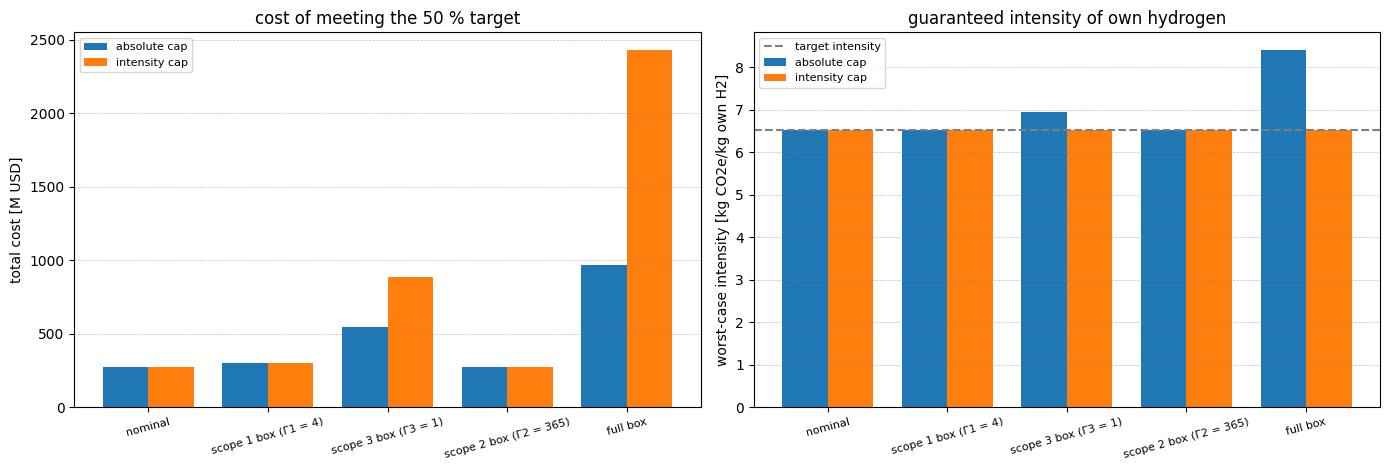

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(cases))
w = 0.38
for k, kind in enumerate(('absolute', 'intensity')):
    sub = cmp.xs(kind, level='cap type')
    axes[0].bar(x + (k - 0.5) * w, sub['cost [M USD]'], w, label=f'{kind} cap')
    axes[1].bar(x + (k - 0.5) * w, sub['worst-case intensity'], w, label=f'{kind} cap')
axes[1].axhline(INT, color='gray', linestyle='--', label='target intensity')
for ax, ylabel, title in zip(axes, ['total cost [M USD]', 'worst-case intensity [kg CO2e/kg own H2]'],
                             ['cost of meeting the 50 % target', 'guaranteed intensity of own hydrogen']):
    ax.set_xticks(x)
    ax.set_xticklabels([c[0] for c in cases], rotation=15, fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5, axis='y')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
with open('Gurobipy_intensity_cap_results.pkl', 'wb') as f:
    pickle.dump({'comparison': cmp, 'GWP0': GWP0, 'I0': I0, 'CAP': CAP, 'INT': INT}, f)
print('saved Gurobipy_intensity_cap_results.pkl')

saved Gurobipy_intensity_cap_results.pkl


## Using the intensity cap elsewhere

- deterministic sweep: `m.add_gwp_cap(intensity=I0 * (1 - pct / 100))` instead of `add_gwp_reduction(...)`;
- robust counterpart: `m.add_robust_gwp_cap(intensity=..., gamma={...})`;
- scenario tree: `tree_model.add_gwp_cap(intensity=..., mode='each')` imposes the intensity in every scenario,
  `mode='expected'` on the probability-weighted hydrogen and emissions.

`results()` now reports `H2_delivered`, `H2_penalty`, `H2_own` and `gwp_intensity`; `robust_values()` reports the
nominal and worst-case intensity; the tree's `scenario_table()` has `h2_own`, `h2_penalty` and `intensity` columns.